## Compare custom models with those that exist in scikit learn

1. Linear Regression

In [1]:
# Generate a random dataset
import numpy as np

rng = np.random.default_rng(seed=42)
m = 200
X = 2 * rng.random((m, 1))
y = 4 + 3 * X + rng.standard_normal((m, 1))

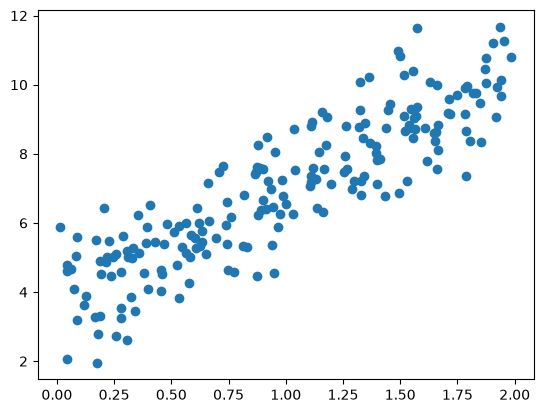

In [2]:
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.show()

In [3]:
# train a scikit learn model
from sklearn.linear_model import LinearRegression

sk_model_reg = LinearRegression()
sk_model_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.33]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.69]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[7.96]


In [4]:
sk_model_reg.score(X, y)

0.7793188483845389

In [5]:
sk_model_reg.intercept_, sk_model_reg.coef_

(array([3.69084138]), array([[3.32960458]]))

In [6]:
# train our custom model
from nanofit.linear_models import LinearRegression

custom_reg_model = LinearRegression()
custom_reg_model.fit(X, y)

,method,'normal'
,n_epochs,1000
,lr,0.01
Name,Type,Value
coeff_,"ndarray[float64](1,)",[3.33]
intercept_,float64,3.691
theta_,"ndarray[float64](2, 1)","[[3.69], [3.33]]"


In [7]:
custom_reg_model.score(X, y)

np.float64(0.9958085506981226)

In [8]:
custom_reg_model.intercept_, custom_reg_model.coeff_

(np.float64(3.690841383464254), array([3.32960458]))

In [9]:
np.isclose(custom_reg_model.intercept_, sk_model_reg.intercept_) and np.isclose(custom_reg_model.coeff_, sk_model_reg.coef_)

array([[ True]])

The two models have the same parameters, however our custom model seems to score higher than the scikit learn model

In [10]:
# plot predictions
from nanofit.utils import add_dummy_feature
X_new = np.array([[0], [2]])
y_predict_sk = sk_model_reg.predict(X_new)
y_predict_custom = custom_reg_model.predict(X_new)

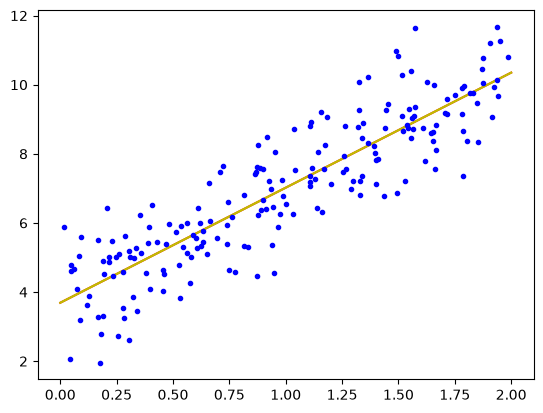

In [11]:
plt.plot(X_new, y_predict_sk, "r-", label="Scikit Learn")
plt.plot(X_new, y_predict_custom, "y-", label="Nanofit")
plt.plot(X, y, "b.")

They fit the data the same way

In [12]:
from sklearn.metrics import mean_squared_error, r2_score
from nanofit.metrics import mse
print(mean_squared_error(y, sk_model_reg.predict(X)), mse(y, custom_reg_model.predict(X)))
print(np.allclose(sk_model_reg.intercept_, custom_reg_model.intercept_), np.allclose(sk_model_reg.coef_, custom_reg_model.coeff_))

0.9958085506981226 0.9958085506981226
True True


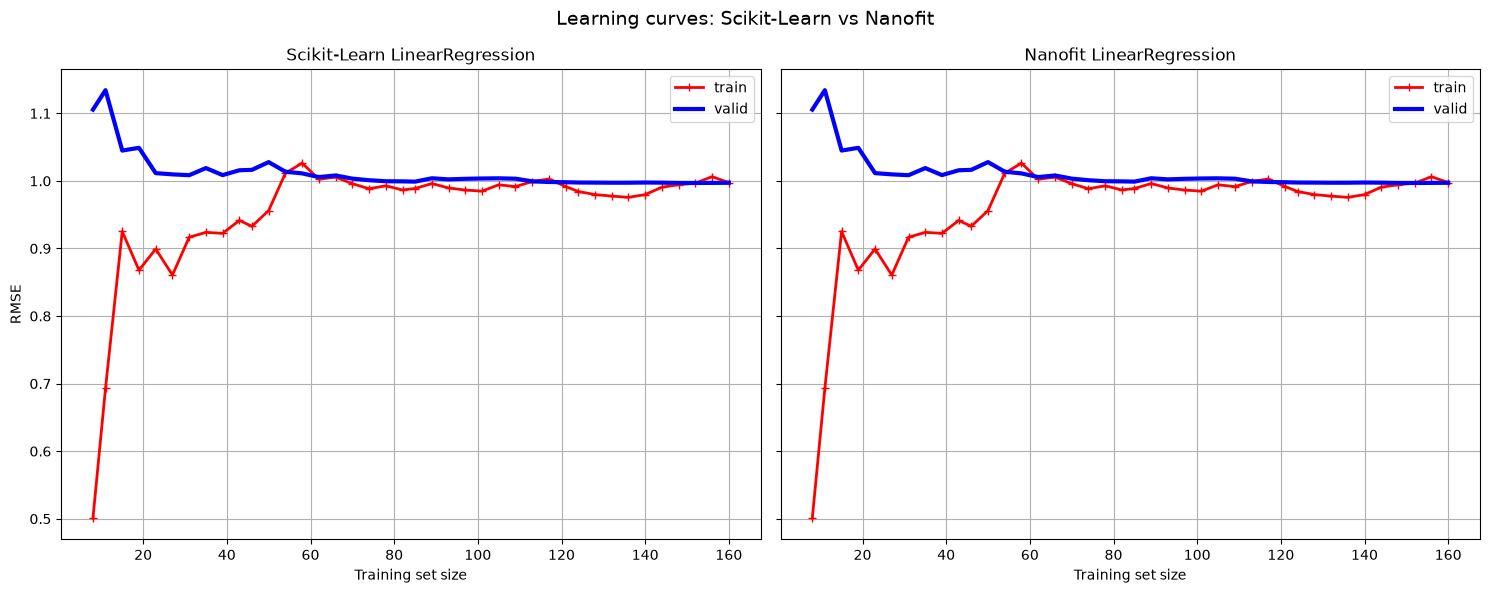

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LinearRegression as SkLR
from nanofit.linear_models import LinearRegression as MyLR

def get_curve(model):
    sizes, tr, va = learning_curve(
        model, X, y.ravel(),
        train_sizes=np.linspace(0.05, 1.0, 40), cv=5,
        scoring="neg_root_mean_squared_error")
    return sizes, -tr.mean(axis=1), -va.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, name, model in zip(axes, ["Scikit-Learn", "Nanofit"], [SkLR(), MyLR()]):
    sizes, tr_err, va_err = get_curve(model)
    ax.plot(sizes, tr_err, "r-+", linewidth=2, label="train")
    ax.plot(sizes, va_err, "b-", linewidth=3, label="valid")
    ax.set_title(f"{name} LinearRegression")
    ax.set_xlabel("Training set size")
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel("RMSE")
fig.suptitle("Learning curves: Scikit-Learn vs Nanofit", fontsize=14)
plt.tight_layout()
plt.show()

The scores are identical, so the implementation works. Let's try the gradient descent version of the model

In [14]:
custom_reg_model_grad = LinearRegression(method="grad")
custom_reg_model_grad.fit(X, y)

,method,'grad'
,n_epochs,1000
,lr,0.01
Name,Type,Value
coeff_,"ndarray[float64](1,)",[3.35]
intercept_,float64,3.671
theta_,"ndarray[float64](2, 1)","[[3.67], [3.35]]"


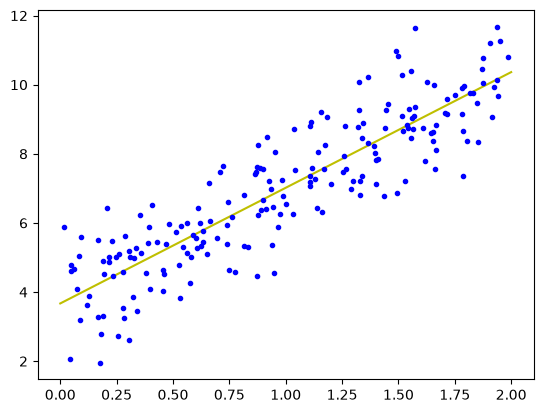

In [15]:
y_predict_custom = custom_reg_model_grad.predict(X_new)
plt.plot(X_new, y_predict_custom, "y-", label="Nanofit")
plt.plot(X, y, "b.")

In [16]:
print(mean_squared_error(y, sk_model_reg.predict(X)), mse(y, custom_reg_model_grad.predict(X)))

0.9958085506981226 0.9959137280101206


Still the same performance as the normal equation version of gradient descent

2. SGDRegressor

In [17]:
from sklearn.linear_model import SGDRegressor

sk_sgd = SGDRegressor(random_state=42)
sk_sgd.fit(X, y.ravel())

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1


In [18]:
mean_squared_error(y.ravel(), sk_sgd.predict(X))

1.0070619636874358

In [19]:
from nanofit.linear_models import SGDRegressor

custom_sgd = SGDRegressor(random_state=42)
custom_sgd.fit(X, y)

,random_state,42
,t1,5
,t2,50
,n_epochs,1000
Name,Type,Value
coeff_,"ndarray[float64](1,)",[3.33]
intercept_,float64,3.691
theta_,"ndarray[float64](2, 1)","[[3.69], [3.33]]"


In [20]:
custom_sgd.score(X, y)

np.float64(0.9958085526141639)

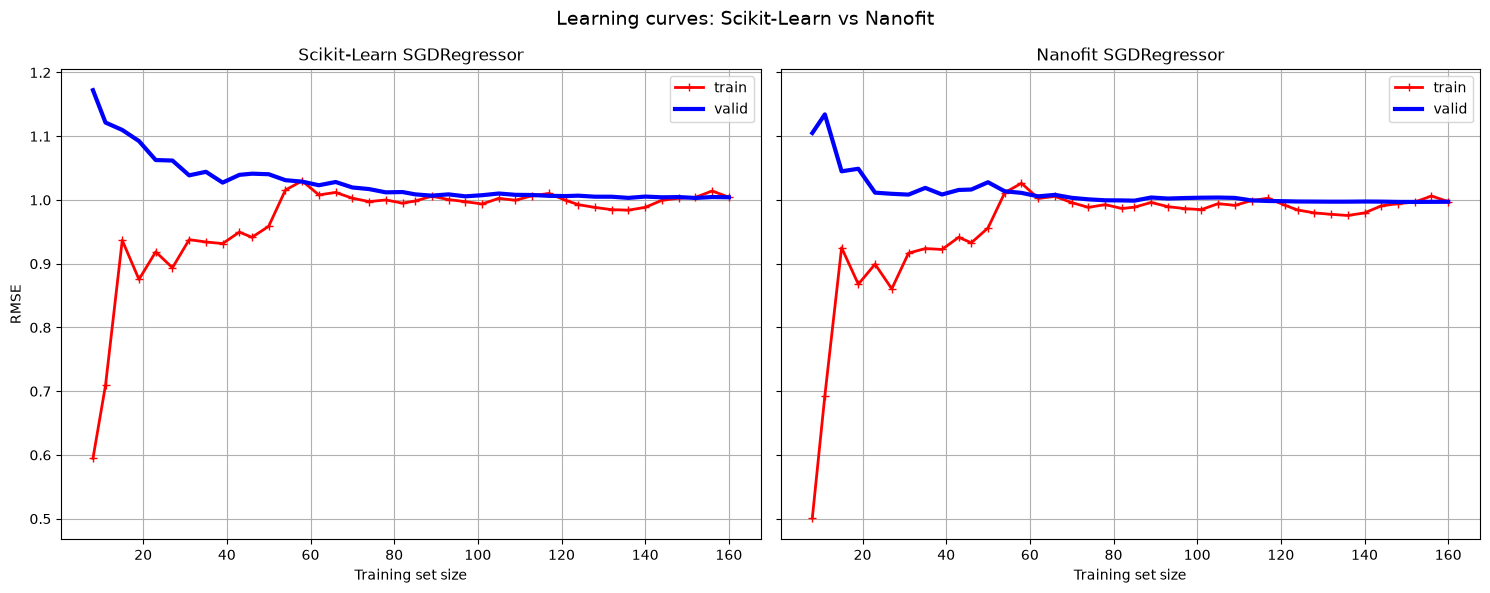

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import SGDRegressor as SkSGD
from nanofit.linear_models import SGDRegressor as MySGD

def get_curve(model):
    sizes, tr, va = learning_curve(
        model, X, y.ravel(),
        train_sizes=np.linspace(0.05, 1.0, 40), cv=5,
        scoring="neg_root_mean_squared_error")
    return sizes, -tr.mean(axis=1), -va.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, name, model in zip(axes, ["Scikit-Learn", "Nanofit"], [SkSGD(), MySGD()]):
    sizes, tr_err, va_err = get_curve(model)
    ax.plot(sizes, tr_err, "r-+", linewidth=2, label="train")
    ax.plot(sizes, va_err, "b-", linewidth=3, label="valid")
    ax.set_title(f"{name} SGDRegressor")
    ax.set_xlabel("Training set size")
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel("RMSE")
fig.suptitle("Learning curves: Scikit-Learn vs Nanofit", fontsize=14)
plt.tight_layout()
plt.show()

Our custom one beats sklearn slightly

3. Mini Batch

In [21]:
# sklearn supports mini batch still using SGD
from sklearn.linear_model import SGDRegressor

sk_mini = SGDRegressor(random_state=42)

batch_size = 30
X_batches = np.array_split(X, len(X) // batch_size)
y_batches = np.array_split(y.ravel(), len(y) // batch_size)

for epoch in range(200):
    for X_batch, y_batch in zip(X_batches, y_batches):
        sk_mini.partial_fit(X_batch, y_batch)

In [22]:
mean_squared_error(y.ravel(), sk_mini.predict(X))

0.9958086013032192

In [23]:
from nanofit.linear_models import MBRegressor

custom_mini = MBRegressor(batch_size=30, n_epochs=200, random_state=42)
custom_mini.fit(X,y)

,batch_size,30
,n_epochs,200
,random_state,42
,t1,5
,t2,50
Name,Type,Value
coeff_,"ndarray[float64](1,)",[3.33]
intercept_,float64,3.688
theta_,"ndarray[float64](2, 1)","[[3.69], [3.33]]"


In [24]:
custom_mini.score(X, y)

np.float64(0.9958119077409477)